## Факторный анализ

In [1]:
pip install factor_analyzer

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
from factor_analyzer import FactorAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import kagglehub

**Подгрузка данных**

In [3]:
df_path = kagglehub.dataset_download("hufe09/winequality", path = "winequality-white.csv")

In [4]:
df = pd.read_csv(df_path, sep=';')
print("Размерность данных:", df.shape)
print("\nПервые несколько строк данных:")
print(df.head())

Размерность данных: (4898, 12)

Первые несколько строк данных:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0

**Исключение целевой переменной (качество белового вина) и стандартизация данных.**

In [5]:
# Подготовка данных
# Исключаем целевую переменную 'quality' и стандартизируем данные
X = df.drop('quality', axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

In [6]:
# Проверка адекватности выборки
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
print("\nТест сферичности Бартлетта:")
print(f"p-значение: {p_value}")


Тест сферичности Бартлетта:
p-значение: 0.0


p - значение меньше 0,05, соответсвенно данные подходят для факторного анализа

**Определение оптимального количества факторов для анализа**

In [7]:
fa = FactorAnalyzer(rotation=None, n_factors=X_scaled.shape[1])
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,11
,rotation,None
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [8]:
# проверка кайзера
# Собственные значения
ev, v = fa.get_eigenvalues()
print("\nСобственные значения:")
print(ev)


Собственные значения:
[3.22225389 1.57523993 1.22167134 1.01852235 0.97333458 0.93874151
 0.72659802 0.59935848 0.41414367 0.28948714 0.02064909]


Это значения, которые указывают на значимость каждого фактора. Высокие собственные значения указывают на то, что соответствующий фактор объясняет значительную часть вариации. Проверка Кайзера: Факторы с собственными значениями > 1 считаются значимыми, соответсвенно мы имеем 4 значимых собственных значения, наиболее значимым из которых является 3,22)

**Визуализация графика собственных значений**

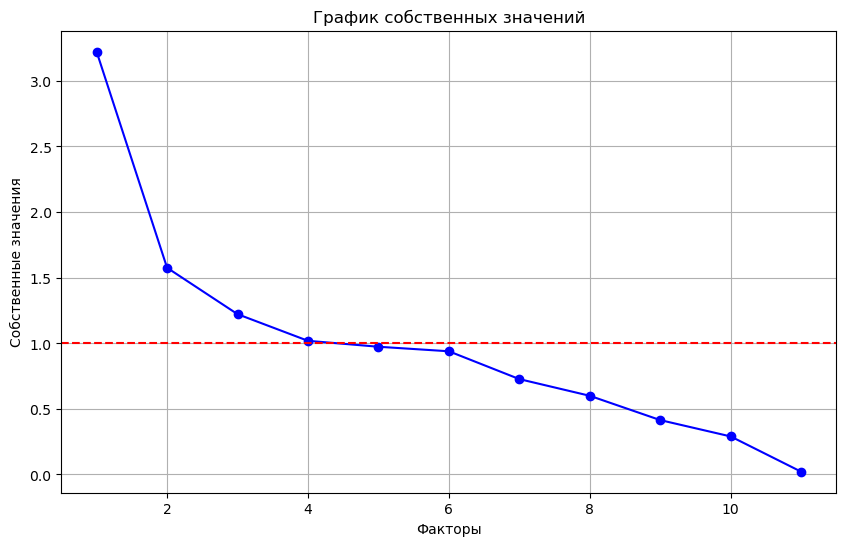

In [9]:
# Визуализация графика собственных значений
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(ev)+1), ev, 'bo-')
plt.axhline(y=1, color='r', linestyle='--')
plt.title('График собственных значений')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')
plt.grid(True)
plt.show()

График отражает, что 4 фактора с собственными значениями > 1, это обосновывает выбор 4 факторов для анализа.

**Факторный анализ varimax**

In [10]:
# Проведение факторного анализа
n_factors = 4
fa = FactorAnalyzer(rotation='varimax', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'varimax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


На основе графика и выведенных собственных значений делаем вывод о количестве факторов - 4.

**Факторные нагрузки**

In [11]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.066450 -0.062253  0.884144 -0.068103
volatile acidity     -0.029877 -0.006771 -0.031128  0.094592
citric acid           0.065612  0.102896  0.339265 -0.029624
residual sugar        0.355717  0.158206  0.184941  0.908726
chlorides             0.345251  0.110405  0.057764 -0.050092
free sulfur dioxide   0.130852  0.610295  0.022810  0.146297
total sulfur dioxide  0.278714  0.889655  0.138129  0.160918
density               0.697336  0.242071  0.256645  0.536565
pH                   -0.068175  0.109366 -0.472854 -0.069944
sulphates             0.024580  0.162167 -0.045616 -0.047858
alcohol              -0.978517 -0.165601 -0.086022 -0.068804


Фактор 1 имеет значимые взаимосвязи ( больше 0,4) с density и alcohol. 
Фактор 2 имеет значимые взаимосвязи с free sulfur dioxide и total sulfur dioxide.
Фактор 3 имеет значимые взаимосвязи с fixed acidity и pH.
Фактор 4 имеет значимые взаимосвязи с residual sugar и density. 

**Визуализация факторных нагрузок**

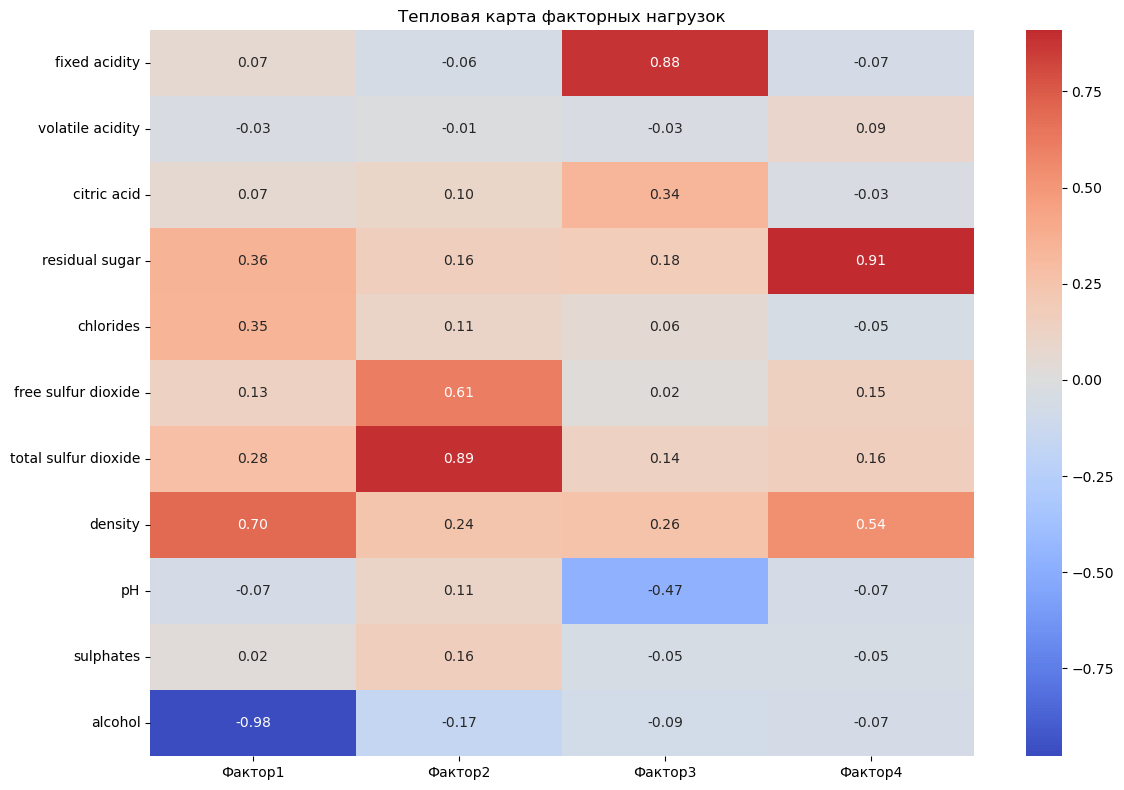

In [12]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

Данный график более наглядно отражает наиболее значимые факторные нагрузки (силу их связи с выделеными факторами).

**Тепловая карта факторных нагрузок**

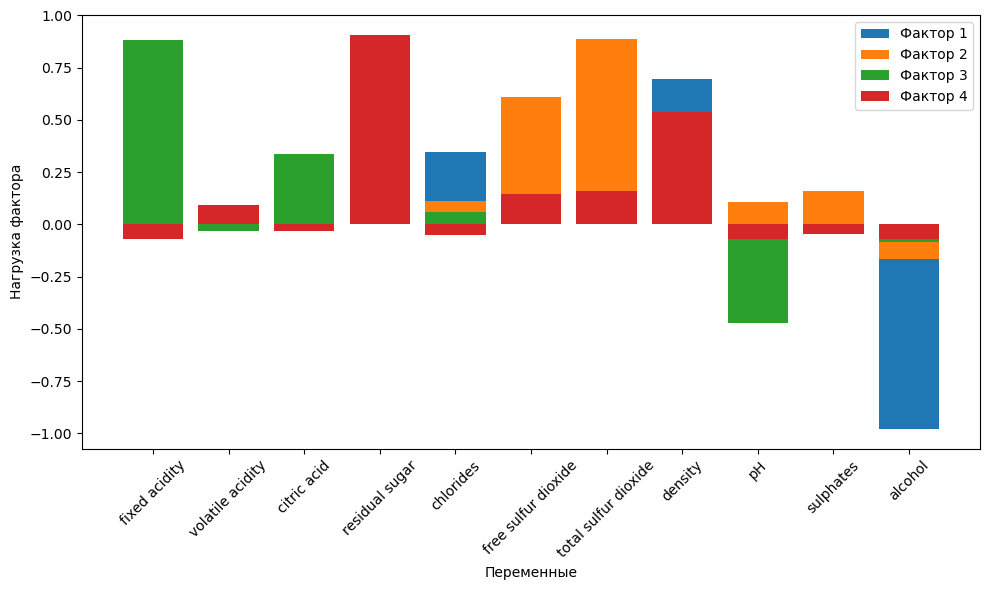

In [13]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

Данный график наглядно показывает структуру факторных нагрузок. Помогает выявить кластеры связанных переменных.

**Объяснение дисперсии**

In [14]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.799175        0.163561        0.163561
Фактор2     1.339956        0.121814        0.285376
Фактор3     1.253859        0.113987        0.399363
Фактор4     1.189871        0.108170        0.507533


SS Loadings - показывает, сколько дисперсии в данных объясняется каждым из факторов.
Proportion Var: Доля вариации, объясняемая каждым фактором. Это значение показывает, какую часть общей дисперсии данных объясняет каждый фактор.
Cumulative Var: Кумулятивная доля вариации, объясняемая факторами до данного момента. Это значение показывает, насколько в совокупности факторы объясняют дисперсию данных.

Вывод: Первый и второй факторы являются самыми значительными, так как они объясняют наибольшую долю общей дисперсии по сравнению с третьим и четвертым факторами.
Четыре фактора в совокупности объясняют 50.75% общей дисперсии данных. Это указывает на то, что хотя факторы имеют значительное влияние на объяснение вариации, остается еще 49.15% дисперсии, которые могут быть объяснены другими факторами или случайными вариациями.

**Общности**

In [15]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.794640
volatile acidity      0.010855
citric acid           0.130871
residual sugar        1.011549
chlorides             0.137234
free sulfur dioxide   0.411506
total sulfur dioxide  0.914142
density               0.898645
pH                    0.245092
sulphates             0.031274
alcohol               0.997053


Чем выше значение общности, тем больше переменный признак связан с выявленными факторами, соответственно наиболее связанными с факторами признаками являются признаки ( общность больше 0,7): fixed acidity, residual sugar, total sulfur dioxide, density и alcohol. Умеренной связью (0,4-0,7) с факторами обладает признак free sulfur dioxide. А все остальные признаки (< 0,4) являются слабо связанными с выявленными факторами.

**Круговая диаграмма кумулятивной объясненной дисперсии**

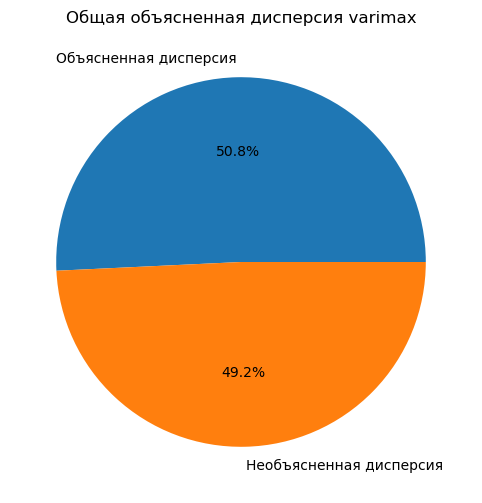

In [16]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия varimax')
plt.show()

Как можно заметить на простой диаграмме в совокупности выявленные факторы объясняют дисперсию данных на 50,8%. В дальнейшем именно это совокупное обЪяснение факторами дисперсии и будет сравниваться для выявляения наилучшего вида ротации.

**Факторный анализ promax**

In [17]:
n_factors = 4
fa = FactorAnalyzer(rotation='promax', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'promax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [18]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.095453 -0.051951  0.928433 -0.109676
volatile acidity      0.038150 -0.000138 -0.028532  0.100406
citric acid           0.024010  0.107554  0.354500 -0.049950
residual sugar       -0.228483  0.076026  0.097472  0.888529
chlorides            -0.374214  0.023039 -0.016559 -0.083952
free sulfur dioxide   0.038503  0.632472  0.027766  0.133101
total sulfur dioxide -0.031473  0.900674  0.131995  0.128867
density              -0.641607  0.072076  0.102682  0.475765
pH                   -0.003497  0.120965 -0.480860 -0.047601
sulphates             0.000192  0.169087 -0.043387 -0.050248
alcohol               1.094249  0.099874  0.144783  0.018757


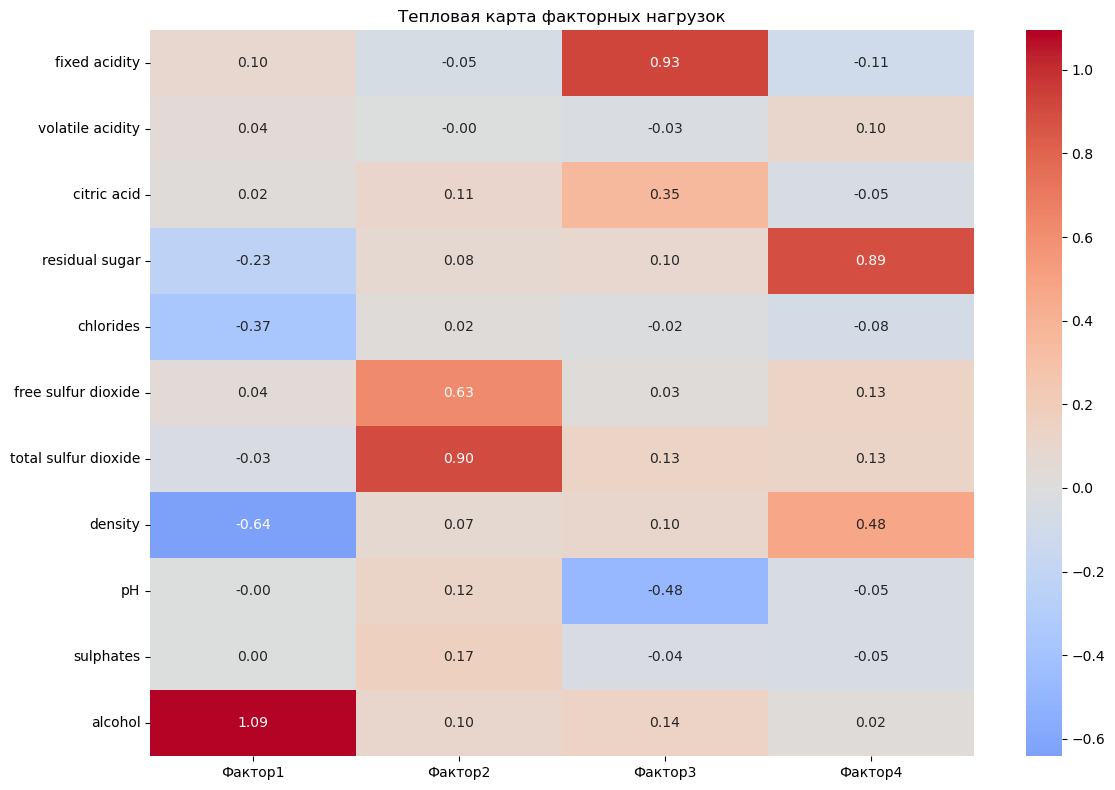

In [19]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

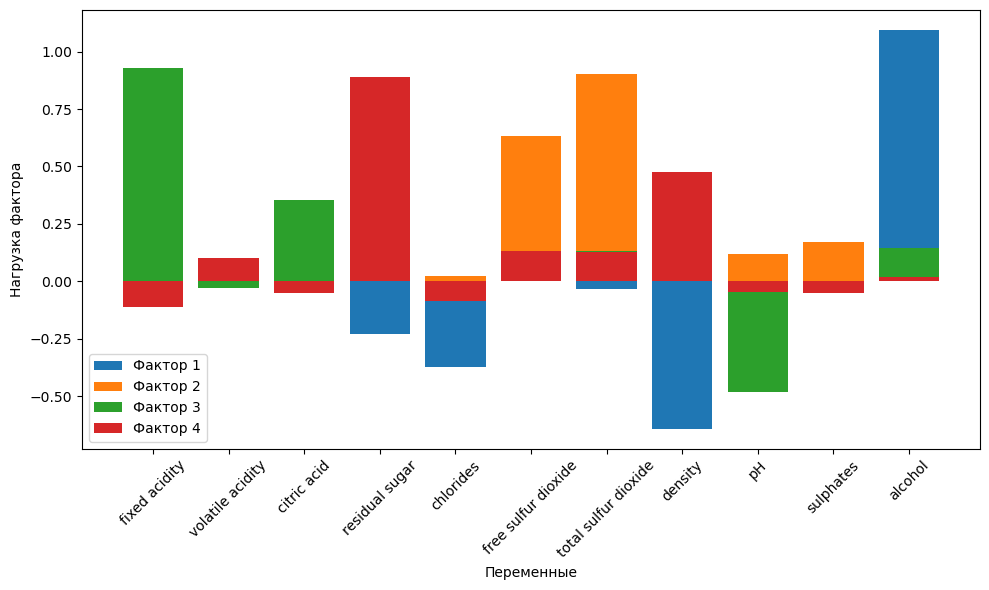

In [20]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [21]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.814910        0.164992        0.164992
Фактор2     1.290204        0.117291        0.282283
Фактор3     1.281056        0.116460        0.398743
Фактор4     1.086954        0.098814        0.497557


In [22]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.885827
volatile acidity      0.012351
citric acid           0.140310
residual sugar        0.856968
chlorides             0.147889
free sulfur dioxide   0.419991
total sulfur dioxide  0.846233
density               0.653750
pH                    0.248137
sulphates             0.032998
alcohol               1.228671


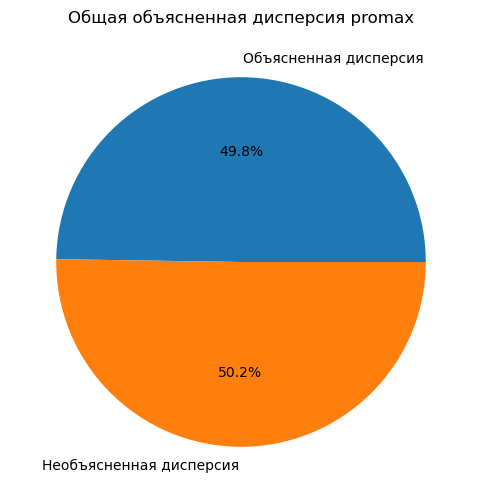

In [23]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия promax')
plt.show()

**Факторный анализ oblimin**

In [24]:
n_factors = 4
fa = FactorAnalyzer(rotation='oblimin', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'oblimin'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [25]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.004290 -0.026086  0.018683  0.898484
volatile acidity     -0.017553  0.113157  0.064944 -0.044812
citric acid           0.139308 -0.043766 -0.008584  0.332002
residual sugar        0.010136  1.021292  0.037680 -0.011525
chlorides             0.073877 -0.102610 -0.368166  0.031746
free sulfur dioxide   0.654491  0.034773  0.062480 -0.062176
total sulfur dioxide  0.954094 -0.011434 -0.011646  0.017016
density               0.098519  0.546298 -0.460543  0.092437
pH                    0.104672 -0.125200  0.001409 -0.465878
sulphates             0.182751 -0.094782 -0.014947 -0.052553
alcohol              -0.006396  0.015452  1.005326  0.012397


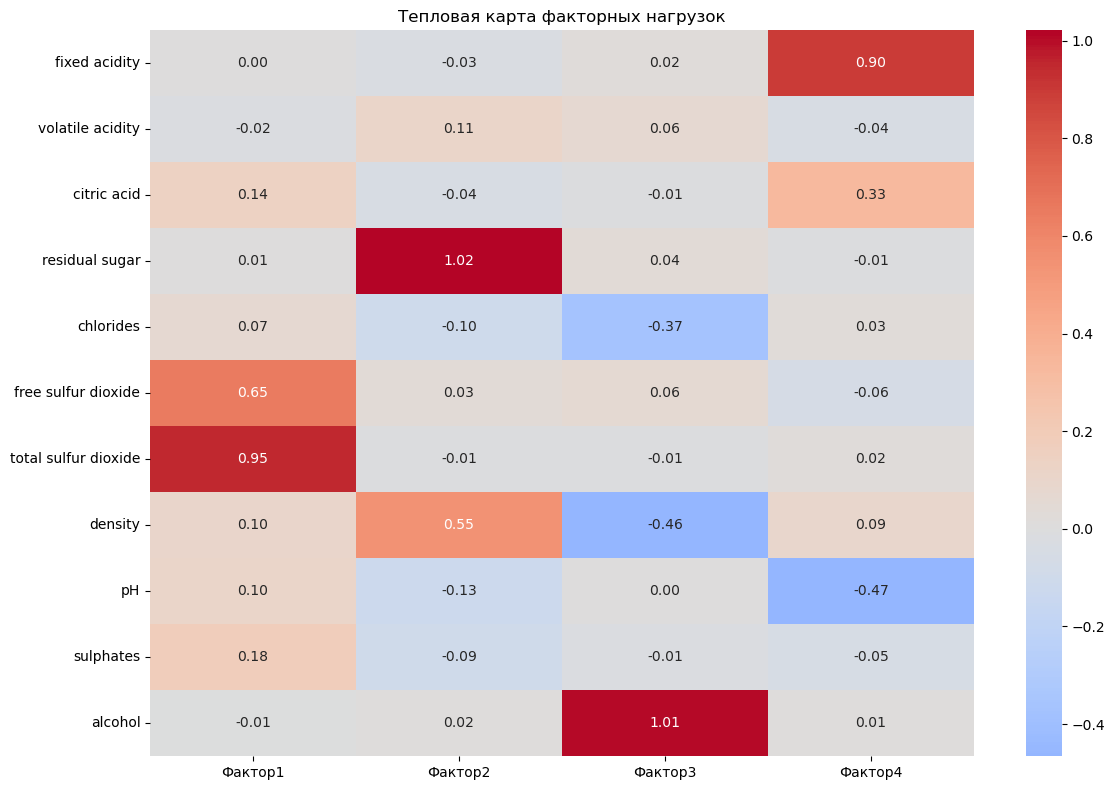

In [26]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

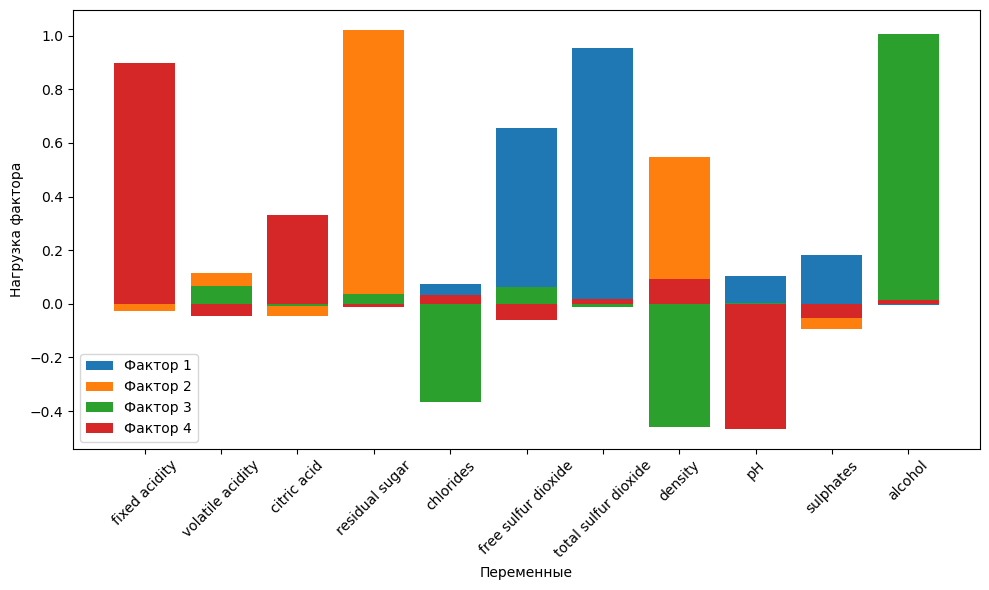

In [27]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [28]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.418048        0.128913        0.128913
Фактор2     1.393646        0.126695        0.255609
Фактор3     1.368652        0.124423        0.380031
Фактор4     1.153306        0.104846        0.484877


In [29]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.808322
volatile acidity      0.019339
citric acid           0.131621
residual sugar        1.044693
chlorides             0.152541
free sulfur dioxide   0.437337
total sulfur dioxide  0.910851
density               0.528792
pH                    0.243675
sulphates             0.045367
alcohol               1.011114


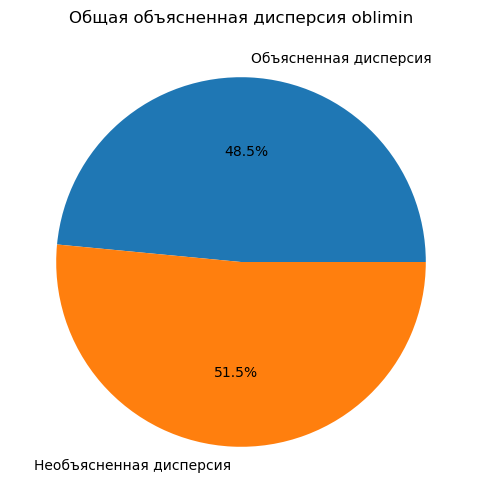

In [30]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия oblimin')
plt.show()

**Факторный анализ oblimax**

In [31]:
n_factors = 4
fa = FactorAnalyzer(rotation='oblimax', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'oblimax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [32]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.258380 -0.801037  0.292792  0.022192
volatile acidity      0.010696  0.030256 -0.054288  0.082934
citric acid           0.183747 -0.244643  0.193017 -0.001261
residual sugar        0.798135 -0.013283 -0.382662  0.477412
chlorides             0.283368  0.003538  0.018607 -0.237860
free sulfur dioxide   0.447316  0.293583  0.334491  0.115495
total sulfur dioxide  0.720697  0.333995  0.524915  0.087463
density               0.921166 -0.058355 -0.216008  0.005777
pH                   -0.175005  0.458044 -0.038482 -0.056392
sulphates             0.055520  0.116396  0.116431 -0.032969
alcohol              -0.809133 -0.019800  0.187250  0.553988


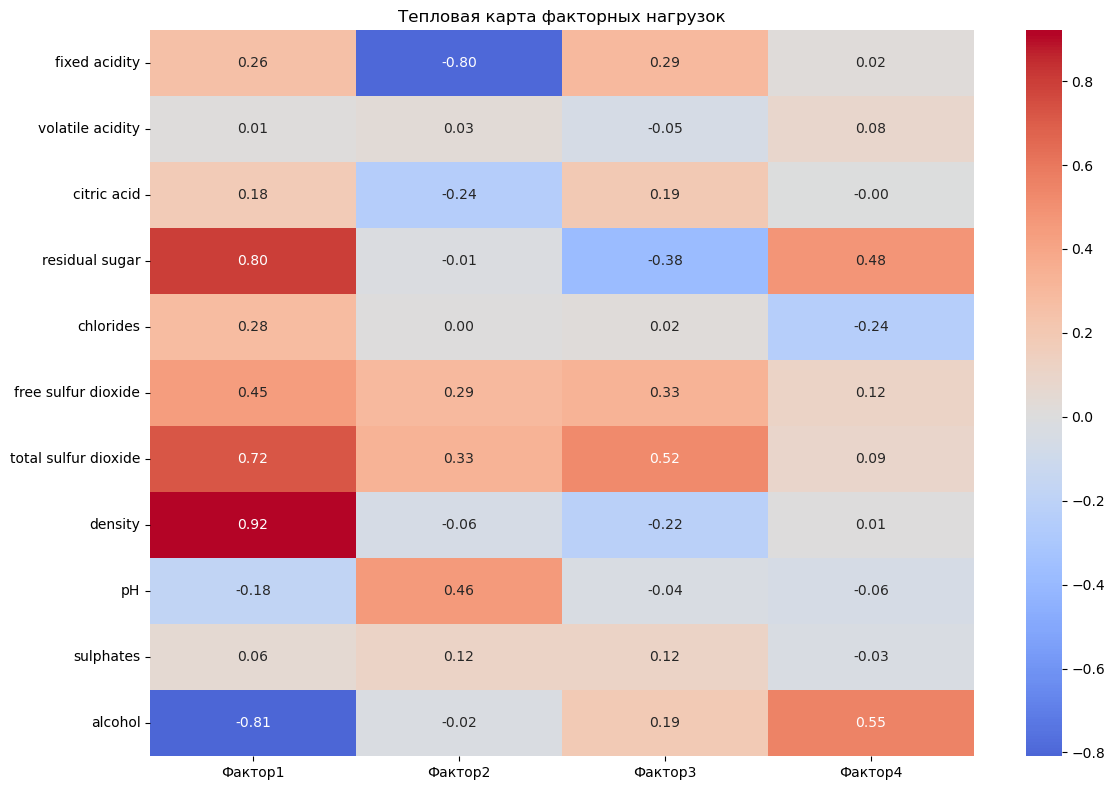

In [33]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

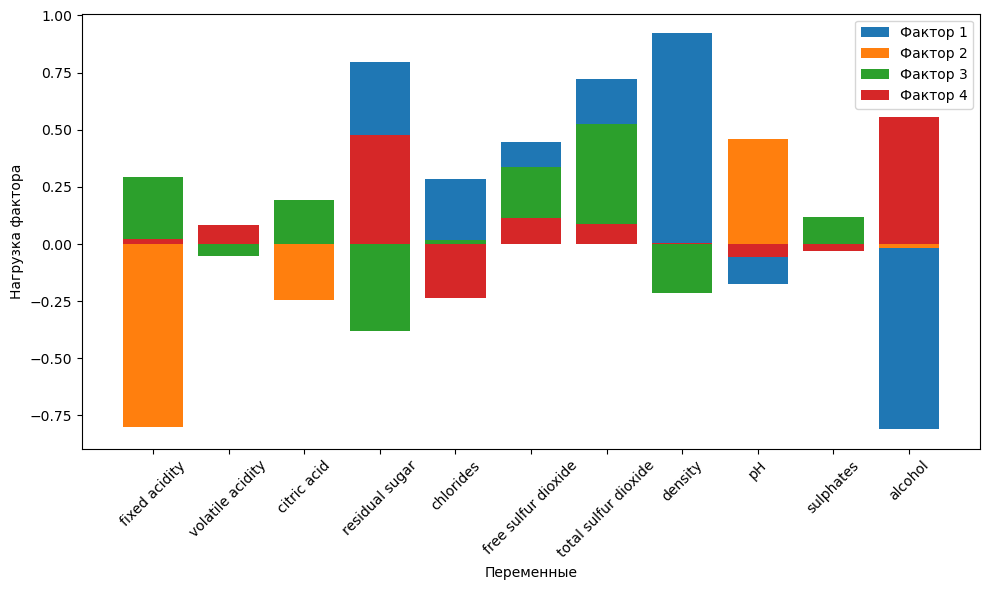

In [34]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [35]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     3.074403        0.279491        0.279491
Фактор2     1.127508        0.102501        0.381992
Фактор3     0.756886        0.068808        0.450800
Фактор4     0.624063        0.056733        0.507533


In [36]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.794640
volatile acidity      0.010855
citric acid           0.130871
residual sugar        1.011549
chlorides             0.137234
free sulfur dioxide   0.411506
total sulfur dioxide  0.914142
density               0.898645
pH                    0.245092
sulphates             0.031274
alcohol               0.997053


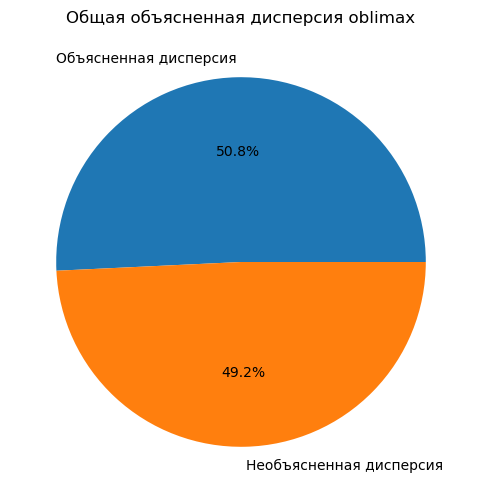

In [37]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия oblimax')
plt.show()

**Факторный анализ quartimin**

In [38]:
n_factors = 4
fa = FactorAnalyzer(rotation='quartimin', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'quartimin'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [39]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.004290 -0.026086  0.018683  0.898484
volatile acidity     -0.017553  0.113157  0.064944 -0.044812
citric acid           0.139308 -0.043766 -0.008584  0.332002
residual sugar        0.010136  1.021292  0.037680 -0.011525
chlorides             0.073877 -0.102610 -0.368166  0.031746
free sulfur dioxide   0.654491  0.034773  0.062480 -0.062176
total sulfur dioxide  0.954094 -0.011434 -0.011646  0.017016
density               0.098519  0.546298 -0.460543  0.092437
pH                    0.104672 -0.125200  0.001409 -0.465878
sulphates             0.182751 -0.094782 -0.014947 -0.052553
alcohol              -0.006396  0.015452  1.005326  0.012397


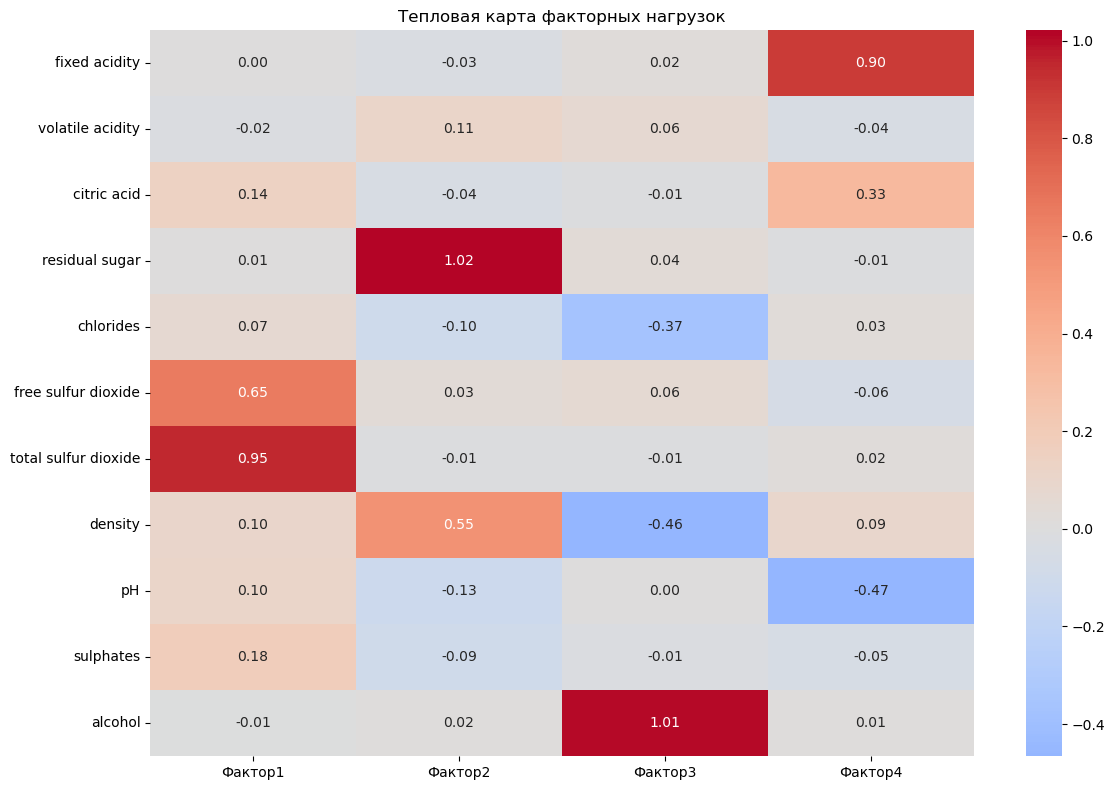

In [40]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

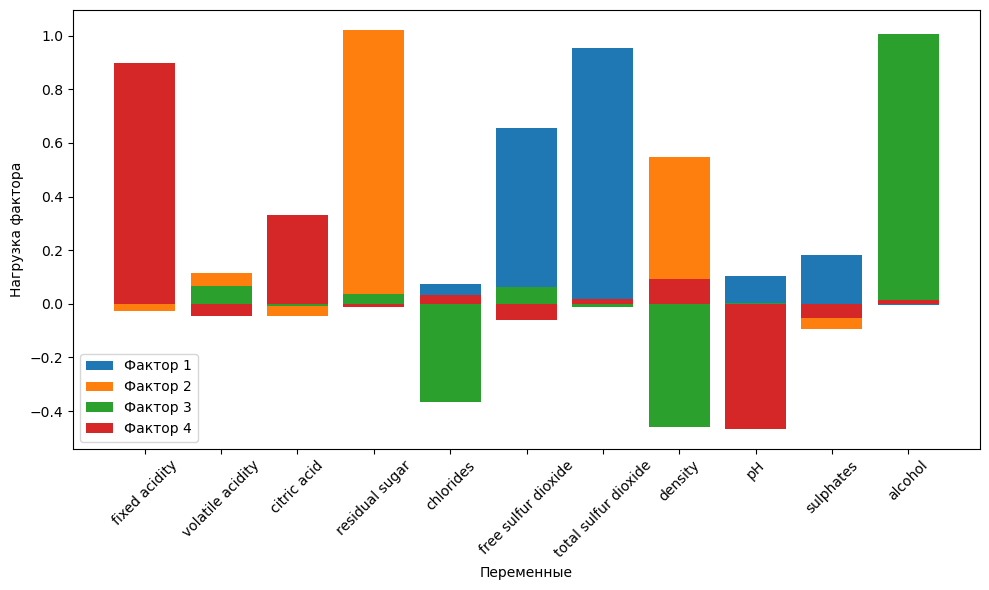

In [41]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [42]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.418048        0.128913        0.128913
Фактор2     1.393646        0.126695        0.255609
Фактор3     1.368652        0.124423        0.380031
Фактор4     1.153306        0.104846        0.484877


In [43]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.808322
volatile acidity      0.019339
citric acid           0.131621
residual sugar        1.044693
chlorides             0.152541
free sulfur dioxide   0.437337
total sulfur dioxide  0.910851
density               0.528792
pH                    0.243675
sulphates             0.045367
alcohol               1.011114


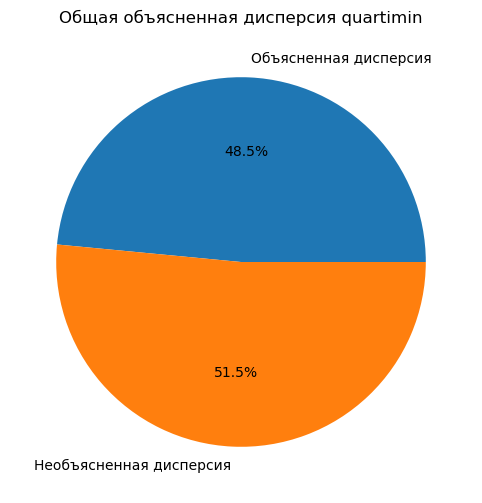

In [44]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия quartimin')
plt.show()

**Факторный анализ quartimax**

In [45]:
n_factors = 4
fa = FactorAnalyzer(rotation='quartimax', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'quartimax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [46]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.081762  0.071524  0.015038  0.884654
volatile acidity      0.080161 -0.048721 -0.013091 -0.043407
citric acid           0.039800  0.066859  0.131996  0.327710
residual sugar        0.984212  0.155061  0.134994  0.024671
chlorides             0.035435  0.347074  0.115584  0.046450
free sulfur dioxide   0.188570  0.094485  0.603143 -0.056903
total sulfur dioxide  0.258735  0.233764  0.889873  0.026052
density               0.709316  0.566052  0.238395  0.135163
pH                   -0.151176 -0.048200  0.072123 -0.463371
sulphates            -0.043677  0.033783  0.159464 -0.052876
alcohol              -0.288066 -0.940850 -0.165837 -0.037013


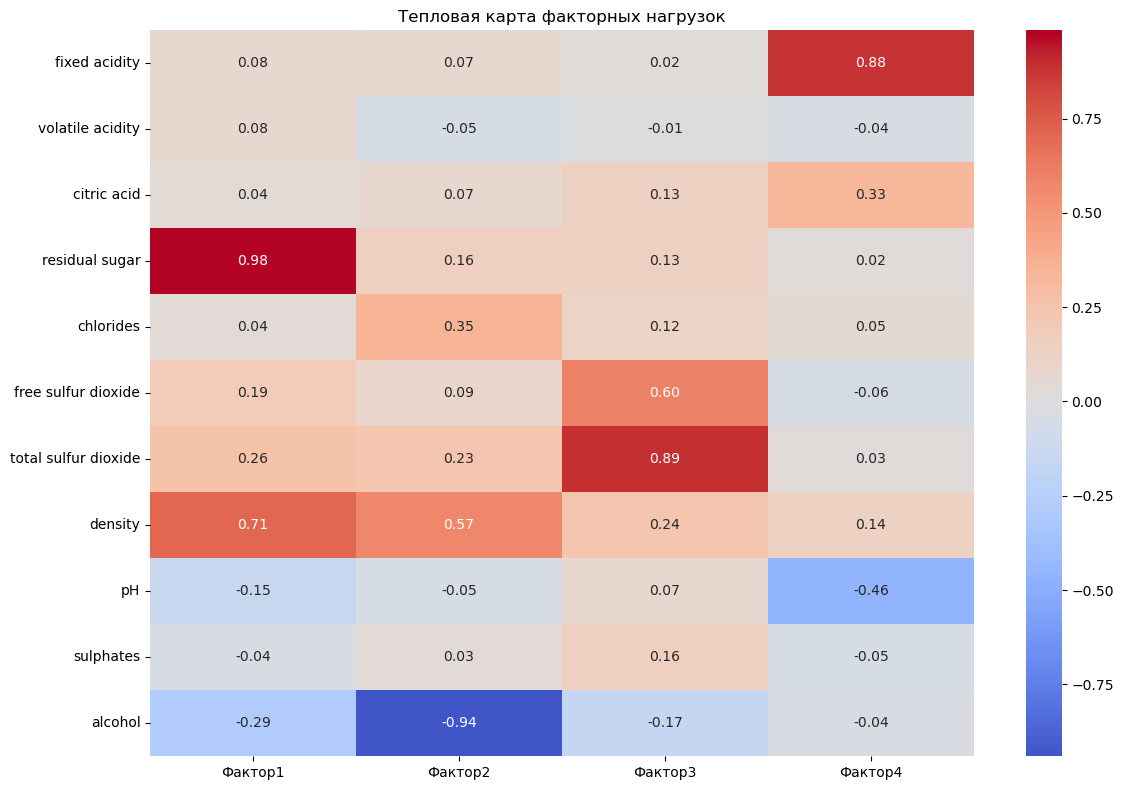

In [47]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

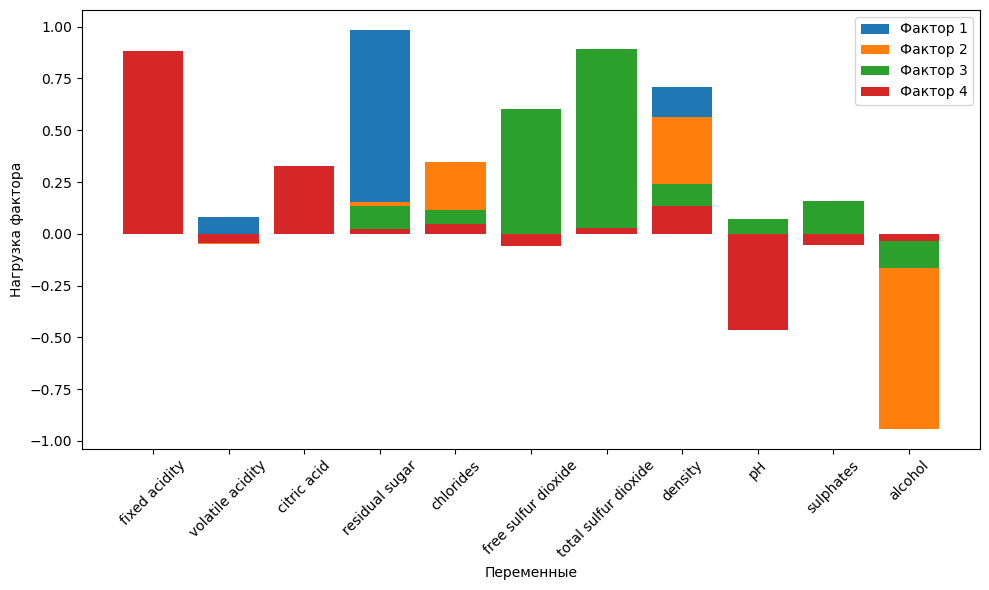

In [48]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [49]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.697999        0.154364        0.154364
Фактор2     1.429116        0.129920        0.284283
Фактор3     1.320023        0.120002        0.404285
Фактор4     1.135722        0.103247        0.507533


In [50]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.794640
volatile acidity      0.010855
citric acid           0.130871
residual sugar        1.011549
chlorides             0.137234
free sulfur dioxide   0.411506
total sulfur dioxide  0.914142
density               0.898645
pH                    0.245092
sulphates             0.031274
alcohol               0.997053


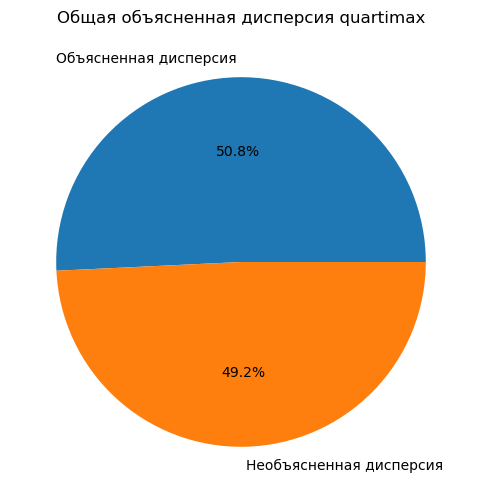

In [51]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия quartimax')
plt.show()

**Факторный анализ equamax**

In [52]:
n_factors = 4
fa = FactorAnalyzer(rotation='equamax', n_factors=n_factors)
fa.fit(X_scaled)

/opt/conda/lib/python3.13/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,n_factors,4
,rotation,'equamax'
,method,'minres'
,use_smc,True
,is_corr_matrix,False
,bounds,"(0.005, ...)"
,impute,'median'
,svd_method,'randomized'
,rotation_kwargs,{}


In [53]:
# Получение факторных нагрузок
factor_loadings = pd.DataFrame(
    fa.loadings_,
    columns=[f'Фактор{i+1}' for i in range(n_factors)],
    index=X.columns
)

print("\nФакторные нагрузки:")
print(factor_loadings)


Факторные нагрузки:
                       Фактор1   Фактор2   Фактор3   Фактор4
fixed acidity         0.081762  0.071524  0.015038  0.884654
volatile acidity      0.080161 -0.048721 -0.013091 -0.043407
citric acid           0.039800  0.066859  0.131996  0.327710
residual sugar        0.984212  0.155061  0.134994  0.024671
chlorides             0.035435  0.347074  0.115584  0.046450
free sulfur dioxide   0.188570  0.094485  0.603143 -0.056903
total sulfur dioxide  0.258735  0.233764  0.889873  0.026052
density               0.709316  0.566052  0.238395  0.135163
pH                   -0.151176 -0.048200  0.072123 -0.463371
sulphates            -0.043677  0.033783  0.159464 -0.052876
alcohol              -0.288066 -0.940850 -0.165837 -0.037013


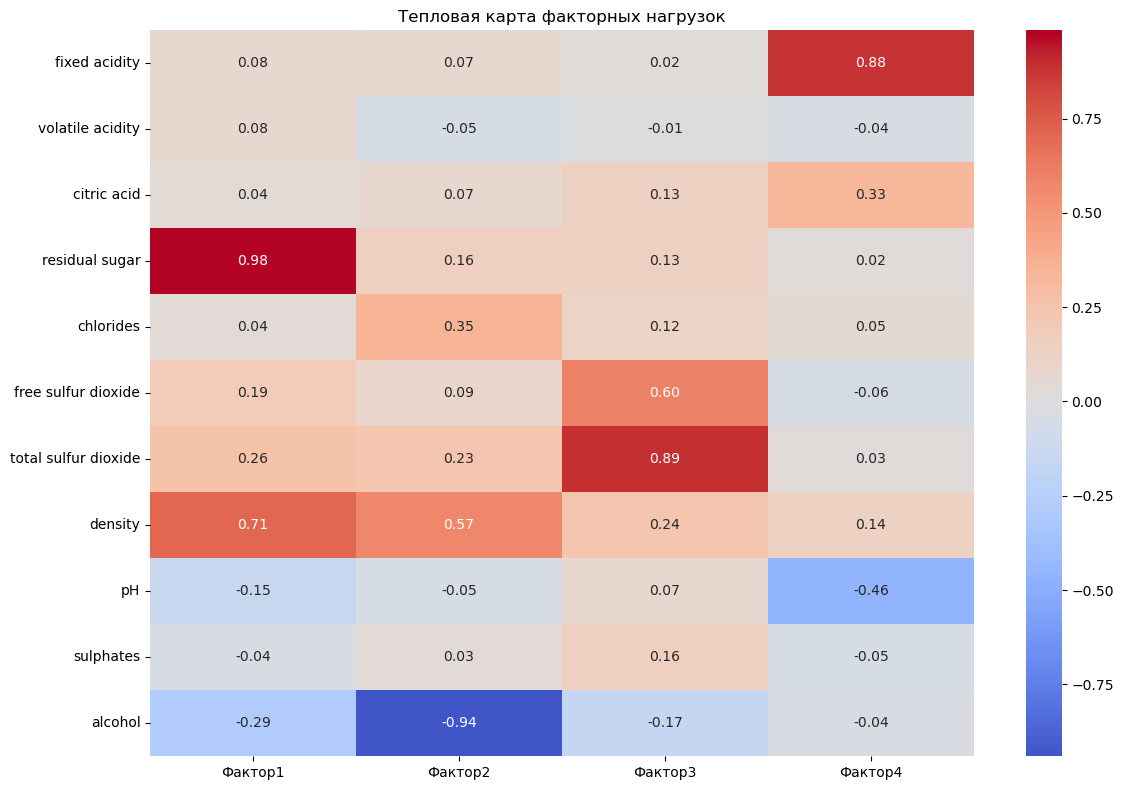

In [54]:
# Визуализация факторных нагрузок
plt.figure(figsize=(12, 8))
sns.heatmap(factor_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Тепловая карта факторных нагрузок')
plt.tight_layout()
plt.show()

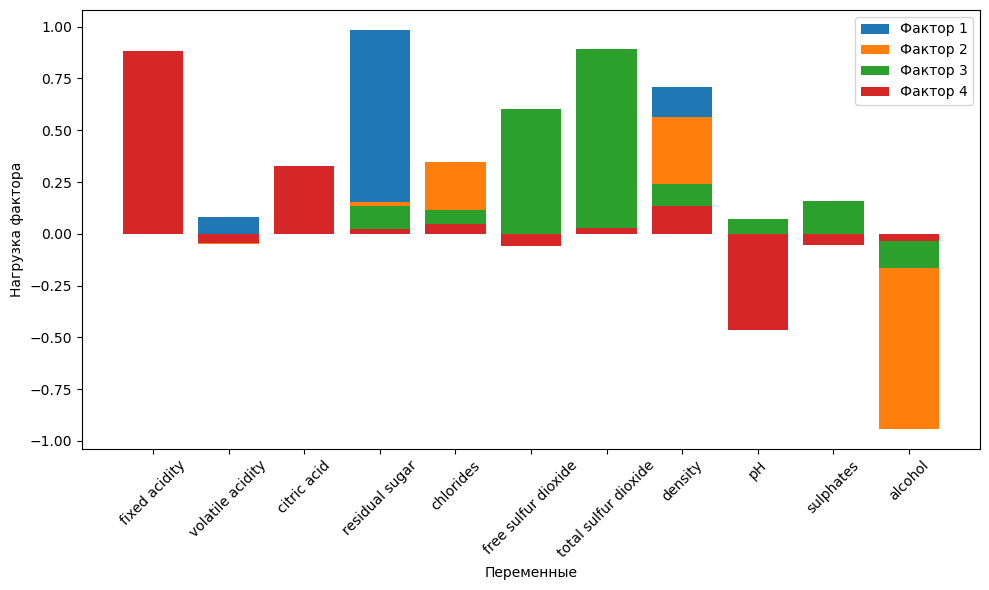

In [55]:
import matplotlib.pyplot as plt

# Получить матрицу факторной нагрузки
factor_loadings = fa.loadings_

# Создать график факторной нагрузки
plt.figure(figsize=(10, 6))
for i in range(n_factors):
    plt.bar(X.columns, factor_loadings[:, i], label=f'Фактор {i+1}')
plt.xlabel('Переменные')
plt.ylabel('Нагрузка фактора')
plt.xticks(rotation=45)  # повернуть названия переменных для лучшей читаемости
plt.legend()
plt.tight_layout()  # чтобы названия переменных не обрезались
plt.show()

In [56]:
variance = pd.DataFrame(
    {
        "SS Loadings": fa.get_factor_variance()[0],
        "Proportion Var": fa.get_factor_variance()[1],
        "Cumulative Var": fa.get_factor_variance()[2]
    },
    index=[f'Фактор{i+1}' for i in range(n_factors)]
)
print("\nОбъясненная дисперсия:")
print(variance)


Объясненная дисперсия:
         SS Loadings  Proportion Var  Cumulative Var
Фактор1     1.697999        0.154364        0.154364
Фактор2     1.429116        0.129920        0.284283
Фактор3     1.320023        0.120002        0.404285
Фактор4     1.135722        0.103247        0.507533


In [57]:
# Общности
communalities = pd.DataFrame(
    {
        'Общность': fa.get_communalities()
    },
    index=X.columns
)
print("\nОбщности:")
print(communalities)


Общности:
                      Общность
fixed acidity         0.794640
volatile acidity      0.010855
citric acid           0.130871
residual sugar        1.011549
chlorides             0.137234
free sulfur dioxide   0.411506
total sulfur dioxide  0.914142
density               0.898645
pH                    0.245092
sulphates             0.031274
alcohol               0.997053


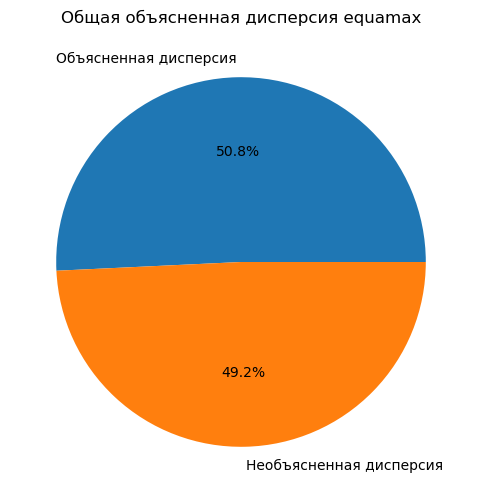

In [58]:
# Круговая диаграмма кумулятивной объясненной дисперсии
plt.figure(figsize=(10, 6))
plt.pie([variance['Proportion Var'].sum(), 1 - variance['Proportion Var'].sum()],
        labels=['Объясненная дисперсия', 'Необъясненная дисперсия'],
        autopct='%1.1f%%')
plt.title('Общая объясненная дисперсия equamax')
plt.show()

При проведении факторного анализа были рассмотрены все 7 видов ротации данных: varimax (orthogonal rotation), promax, (oblique rotation), oblimin (oblique rotation), oblimax (orthogonal rotation), quartimin (oblique rotation), quartimax (orthogonal rotation) и equamax (orthogonal rotation). При 4-х видах ротации были получены лучшие описательные способности дисперсии. ( Дисперсия обЪяснена на 50,75% (50,80%)). Наилучшие виды ротации в факторном анализе:  varimax, equamax, quartimax и oblimax. Так как все 4 вида дали одинаковые "по хорошести" результаты, орпишем один из них. Для описания был выбран метод ротации varimax. Описание факторного анализа с ротацией varimax была описана выше в работе.